# Modelo de reforestación — Parque Eólico Dominica
## 1. Introducción y objetivo
Primera versión del **Entregable 2**, centrada en P1: minimizar un índice provisional de competencia mediante **DSATUR adaptado y búsqueda local**, manteniendo el inventario real y las cuotas finales. Se simulan coordenadas, no cantidades existentes.

El notebook es un experimento reproducible de asignación espacial; **no es un plano de campo ni una predicción de supervivencia**. Todas las coordenadas son simuladas en metros locales. Los resultados guardados provienen de ejecutar las celdas.

**Fuentes locales:** `sources/Presentacion_Socio_Formador.md` (diapositivas 9, 13–18), `Datos-Reto.txt`, `Entregable_2.md`, `Entrega_1.md`, `Entregable_1.md`, `reto_etapas.md`, transcripción de la reunión y tres capturas. Los CSV son extracciones, no observaciones nuevas. `data/fuentes_sha256.json` identifica las versiones consultadas.

La conversación anterior «Replanteamiento del modelo» confirma la decisión de simular posiciones con conteos fijos. Las respuestas antiguas no fueron recuperables como texto completo; se siguen las decisiones explícitas del encargo actual.

**Cómo ejecutar:** abrir este archivo desde la carpeta del proyecto, seleccionar un entorno Python con `requirements.txt` instalado y ejecutar todas las celdas. No se necesita conexión a internet para los cálculos.

## 2. Importación de librerías y configuración
Los parámetros geométricos y de competencia son supuestos modificables. La flexibilidad de cuotas queda desactivada en esta versión; no se simula su activación sin implementarla.

In [2]:
from pathlib import Path
from dataclasses import dataclass, replace, asdict
from time import perf_counter
import json, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.spatial import cKDTree
import networkx as nx
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'data/especies.csv').exists():
    raise FileNotFoundError('Abra Jupyter desde la carpeta que contiene este notebook y data/.')
OUT = ROOT / 'resultados'
OUT.mkdir(exist_ok=True)

@dataclass(frozen=True)
class Config:
    densidad: float = 658.0
    aspecto: float = 1.0        # ancho / alto del rectángulo aproximado
    paso_malla: float = 3.4    # tresbolillo de candidatas, no densidad final
    separacion_min: float = 3.4 # SUPUESTO: aplicar distancia ilustrada a todos los pares
    radio: float = 6.0         # interacción, distinto de la separación física
    semilla: int = 20261014
    escenarios: int = 12
    intentos_local: int = 6000
    max_propuestas_posicion: int = 200000

cfg = Config()
plt.rcParams.update({'figure.figsize':(9,6), 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.dpi':110})
COLORES = ['#2166ac','#67a9cf','#1b7837','#a6dba0','#b2182b',
           '#ef8a62','#762a83','#af8dc3','#8c510a','#666666']
MARCAS = ['o','s','^','D','v','P','X','<','>','h']
def guardar_figura(nombre):
    plt.savefig(OUT / (nombre+'.png'), bbox_inches='tight', dpi=140)
    plt.show()

versiones = {p:importlib.metadata.version(p) for p in
             ['numpy','pandas','matplotlib','networkx','scipy','nbformat','nbclient']}
display(pd.Series(asdict(cfg), name='valor'))
print('Python', platform.python_version(), versiones)

densidad                        658.0
aspecto                           1.0
paso_malla                        3.4
separacion_min                    3.4
radio                             6.0
semilla                    20261014.0
escenarios                       12.0
intentos_local                 6000.0
max_propuestas_posicion      200000.0
Name: valor, dtype: float64

Python 3.12.10 {'numpy': '2.5.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'networkx': '3.7', 'scipy': '1.18.1', 'nbformat': '5.11.1', 'nbclient': '0.11.0'}


## 3. Carga y validación de datos reales
Se normalizan las variantes `Opuntia engelmani → Opuntia engelmannii` y `Opuntia streptacanta → Opuntia streptacantha` en los costos, conservando el orden de la fuente. La moneda no está explicitada en la tabla: se reportan **unidades monetarias (u.m.)**.

Los porcentajes de supervivencia se conservan como contexto, sin convertirlos en coeficientes de competencia. Las tablas de las diapositivas 15 y 17 no permiten asumir sin más la misma base temporal: los individuos de la 17 son decimales normalizados, no microdatos. No se ajusta aquí una cadena de Markov.

La tabla de áreas usa P1–P30; las etiquetas del mapa no coinciden con esa numeración (por ejemplo, 1.28 ha aparece junto a 27). Se usa **P1 de la tabla**, no el polígono rotulado 1 en el mapa. P13=5.05 ha conserva la interpretación editorial pendiente de confirmación.

In [3]:
especies = pd.read_csv(ROOT/'data/especies.csv')
inventario = pd.read_csv(ROOT/'data/inventario.csv')
supervivencia = pd.read_csv(ROOT/'data/supervivencia_porcentajes.csv')
S = especies.especie.tolist()
K = len(S)
assert K == 10 and especies.especie.is_unique
assert especies.objetivo_por_ha.sum() == 658
assert not inventario.isna().any().any()
assert not inventario.duplicated(['poligono','especie']).any()
assert len(inventario) == 300
assert set(inventario.poligono) == set(range(1,31))
assert (inventario.existentes >= 0).all()
assert (inventario.existentes % 1 == 0).all()
assert (inventario.area_ha > 0).all()
assert inventario.groupby('poligono').area_ha.nunique().eq(1).all()
assert all(set(g.especie)==set(S) for _,g in inventario.groupby('poligono'))
areas = inventario.groupby('poligono').area_ha.first()
print(f'Área sumada de la tabla: {areas.sum():.2f} ha; referencia del proyecto: 183 ha.')
display(especies)
display(supervivencia)

def datos_poligono(p, config=cfg):
    if p not in areas.index:
        raise ValueError(f'Polígono {p} no disponible.')
    if config.densidad <= 0:
        raise ValueError('La densidad debe ser positiva.')
    n = inventario[inventario.poligono.eq(p)].set_index('especie').loc[S,'existentes'].to_numpy(int)
    total = int(np.floor(areas.loc[p] * config.densidad + 0.5))
    ideal = total * especies.objetivo_por_ha.to_numpy() / especies.objetivo_por_ha.sum()
    R = np.floor(ideal).astype(int)
    # Restos mayores; empates resueltos por el orden fijo de especies.
    orden = np.argsort(-(ideal-R), kind='stable')
    R[orden[:total-int(R.sum())]] += 1
    if np.any(R < n):
        raise ValueError('Inventario superior a una cuota: no se eliminan plantas ni se trunca el faltante.')
    return float(areas.loc[p]), n, R, R-n

area, n, R, q = datos_poligono(1)
assert np.array_equal(n, [8,46,16,16,11,14,18,12,15,9])
assert (n.sum(), R.sum(), q.sum()) == (165,842,677)
tabla_cuotas = especies[['especie','costo_unitario']].copy()
tabla_cuotas['existentes'] = n
tabla_cuotas['meta_final'] = R
tabla_cuotas['nuevas'] = q
tabla_cuotas['costo_nuevas_um'] = q * especies.costo_unitario.to_numpy()
display(tabla_cuotas)
tabla_cuotas.to_csv(OUT/'cuotas_p1.csv', index=False)

Área sumada de la tabla: 183.01 ha; referencia del proyecto: 183 ha.


,especie,genero,objetivo_por_ha,costo_unitario
0,Agave lechuguilla,Agave,42,26.0
1,Agave salmiana,Agave,196,26.0
2,Agave scabra,Agave,42,26.0
3,Agave striata,Agave,42,26.0
4,Opuntia cantabrigiensis,Opuntia,49,18.0
5,Opuntia engelmannii,Opuntia,38,21.0
6,Opuntia robusta,Opuntia,73,18.0
7,Opuntia streptacantha,Opuntia,64,18.0
8,Prosopis laevigata,Prosopis,86,26.5
9,Yucca filifera,Yucca,26,26.0


,especie,2021,2022,2023
0,Agave lechuguilla,100.0,94.35,92.65
1,Agave salmiana,100.0,95.87,90.82
2,Agave scabra,100.0,82.45,74.53
3,Agave striata,100.0,95.17,91.38
4,Opuntia cantabrigiensis,100.0,92.72,82.87
5,Opuntia engelmannii,100.0,89.86,81.94
6,Opuntia robusta,100.0,95.76,91.98
7,Opuntia streptacantha,100.0,88.60,85.25
8,Prosopis laevigata,100.0,82.14,81.79
9,Yucca filifera,100.0,88.43,72.63


,especie,costo_unitario,existentes,meta_final,nuevas,costo_nuevas_um
0,Agave lechuguilla,26.0,8,54,46,1196.0
1,Agave salmiana,26.0,46,251,205,5330.0
2,Agave scabra,26.0,16,54,38,988.0
3,Agave striata,26.0,16,54,38,988.0
4,Opuntia cantabrigiensis,18.0,11,63,52,936.0
5,Opuntia engelmannii,21.0,14,48,34,714.0
6,Opuntia robusta,18.0,18,93,75,1350.0
7,Opuntia streptacantha,18.0,12,82,70,1260.0
8,Prosopis laevigata,26.5,15,110,95,2517.5
9,Yucca filifera,26.0,9,33,24,624.0


## 4. Definición de conjuntos, parámetros y variables del modelo
Para cada $p\in P=\{1,\ldots,30\}$, $S$ contiene 10 especies, $F_p$ las plantas existentes, $V_p$ las posiciones nuevas y $U_p=F_p\cup V_p$. Cada nodo se identifica como **(polígono, índice local)**. $A_p$ se mide en ha, $n_{ps}$ es inventario conocido y $R_{ps}$ es la meta **final**, incluyendo existentes. La compra es $q_{ps}=R_{ps}-n_{ps}$.

Sea $a_{pfs}=1$ si la planta fija $f$ es de especie $s$ y $x_{pis}\in\{0,1\}$ la asignación nueva. Definimos $y_{pis}=a_{pis}$ en $F_p$ y $y_{pis}=x_{pis}$ en $V_p$:
$$\min J=\sum_p\sum_{\{i,j\}\in E_p} w_{pij}\sum_{s,t\in S} C_{st}y_{pis}y_{pjt},\qquad
w_{pij}=\max(0,1-d_{pij}/r).$$
Cada arista no dirigida se cuenta una sola vez. Descomponemos $J=J_{FF}+J_{FV}+J_{VV}$: $J_{FF}$ es constante dentro de cada escenario.

Restricciones:
$$\sum_s x_{pis}\leq1,\quad n_{ps}+\sum_{i\in V_p}x_{pis}=R_{ps},\quad
\sum_s R_{ps}=T_p=\lfloor A_pD+0.5\rfloor.$$
Las coordenadas deben pertenecer al rectángulo y las plantas ocupadas respetar $d_{pij}\geq d_{\min}$. Las preexistentes no cambian de posición ni especie durante la optimización. En el modelo general, dos candidatas incompatibles exigirían $\sum_s x_{pis}+\sum_s x_{pjs}\leq1$.

**Restricción deliberada del prototipo:** se genera un conjunto amplio de candidatas geométricamente compatibles y se seleccionan exactamente $\sum_s q_{ps}$ mediante dispersión espacial antes de DSATUR. Este subconjunto es $V_p$: todas sus posiciones se ocupan. La heurística optimiza especies sobre posiciones prefijadas; no busca simultáneamente el mejor subconjunto posible. La base aleatoria usa el mismo subconjunto.

Para una extensión con flexibilidad $\epsilon\leq0.10$, las igualdades por especie se sustituirían por $\lceil(1-\epsilon)R_{ps}\rceil\leq n_{ps}+\sum_i x_{pis}\leq\lfloor(1+\epsilon)R_{ps}\rfloor$, conservando $T_p$. **No está implementada todavía:** los intercambios de esta versión preservan cuotas exactas.

**Probabilidad solicitada en Entregable 2:** para estos polígonos, $N_{ps}=n_{ps}$ con probabilidad 1. La densidad observada es $n_{ps}/A_p$; no se ajusta Poisson a inventarios conocidos. Si se elige uniformemente una planta existente de P1, $P(S=s\mid p)=n_{ps}/\sum_t n_{pt}$. Las coordenadas se generan por propuestas uniformes con rechazo por separación: no son puntos independientes ni un proceso Poisson. Una distribución para terrenos nuevos requeriría otro análisis y datos representativos.

In [4]:
probabilidades = pd.DataFrame({'especie':S, 'existentes_por_ha':n/area,
    'P_especie_planta_existente':n/n.sum(),
    'proporcion_meta_fuente':especies.objetivo_por_ha/658})
display(probabilidades)
assert np.isclose(probabilidades.P_especie_planta_existente.sum(),1)

,especie,existentes_por_ha,P_especie_planta_existente,proporcion_meta_fuente
0,Agave lechuguilla,6.25000,0.048485,0.063830
1,Agave salmiana,35.93750,0.278788,0.297872
2,Agave scabra,12.50000,0.096970,0.063830
3,Agave striata,12.50000,0.096970,0.063830
4,Opuntia cantabrigiensis,8.59375,0.066667,0.074468
5,Opuntia engelmannii,10.93750,0.084848,0.057751
6,Opuntia robusta,14.06250,0.109091,0.110942
7,Opuntia streptacantha,9.37500,0.072727,0.097264
8,Prosopis laevigata,11.71875,0.090909,0.130699
9,Yucca filifera,7.03125,0.054545,0.039514


## 5. Construcción del polígono de prueba
Se aproxima el terreno por un rectángulo de área exacta $10^4A_p$ m²; no se deduce su contorno real del mapa. Para aspecto $b/h$, $b=\sqrt{10^4A_p\,\text{aspecto}}$ y $h=10^4A_p/b$.

En una malla triangular ideal, $D(d)=10^4/(\sqrt3\,d^2/2)$. La separación ilustrada de 3.4 m no equivale a 658 ni 524 plantas/ha. Además $658(0.8)=526.4$, no 524. Estas cifras no se corrigen silenciosamente.

Se conserva una malla candidata de 3.4 m, parcialmente ocupada, y se aplica **3.4 m como separación mínima a todos los pares**. Generalizar la distancia ilustrada a todas las especies y a las existentes es un supuesto de simulación, no un dato medido. Se compara su capacidad con una malla cuyo paso corresponde a 658 plantas/ha: descontar las posiciones bloqueadas por las existentes puede hacer insuficiente esa segunda malla. Se conserva la malla más densa de 3.4 m sin ocupar todos sus sitios; nunca se relaja la separación automáticamente.

,densidad_pl_ha,distancia_triangular_ideal_m
0,658,4.189110
1,524,4.694281


Densidad ideal para 3.4 m: 998.8758982519479


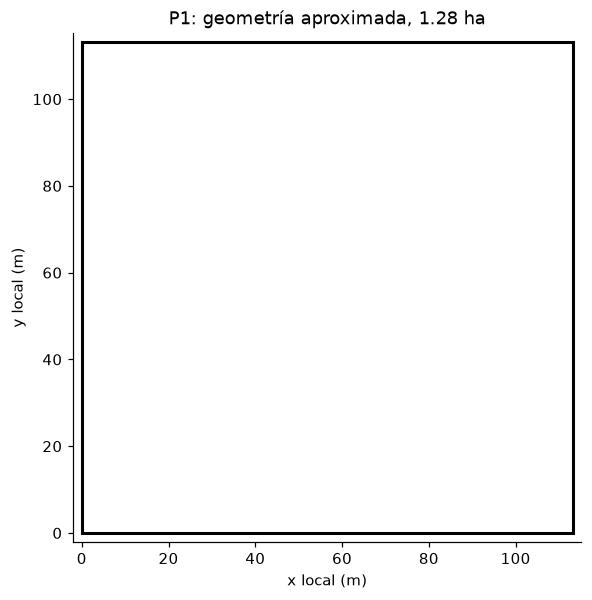

In [5]:
def dimensiones(area_ha, config):
    if area_ha <= 0 or config.aspecto <= 0:
        raise ValueError('Área y aspecto deben ser positivos.')
    ancho = np.sqrt(10000*area_ha*config.aspecto)
    return np.array([ancho, 10000*area_ha/ancho])

limites = dimensiones(area,cfg)
display(pd.DataFrame({'densidad_pl_ha':[658,524],
    'distancia_triangular_ideal_m':np.sqrt(10000/(np.sqrt(3)/2*np.array([658,524])))}))
print('Densidad ideal para 3.4 m:', 10000/(np.sqrt(3)/2*3.4**2))
fig, ax = plt.subplots(figsize=(6,6))
ax.add_patch(plt.Rectangle((0,0),*limites, fill=False, linewidth=2))
ax.set(xlim=(-2,limites[0]+2),ylim=(-2,limites[1]+2),aspect='equal',
       xlabel='x local (m)',ylabel='y local (m)',title='P1: geometría aproximada, 1.28 ha')
guardar_figura('01_poligono')

## 6. Simulación de las posiciones de plantas existentes
Muestreo secuencial con rechazo y una cuadrícula auxiliar para revisar vecinos próximos. Las propuestas son uniformes en el rectángulo; el rechazo introduce repulsión y efectos de borde. Se permutan las etiquetas de especie con los **conteos exactos**. Se limita el número de intentos: agotarlo indica un fallo del generador bajo esos parámetros, no una prueba matemática de imposibilidad. Los escenarios agrupados quedan como extensión.

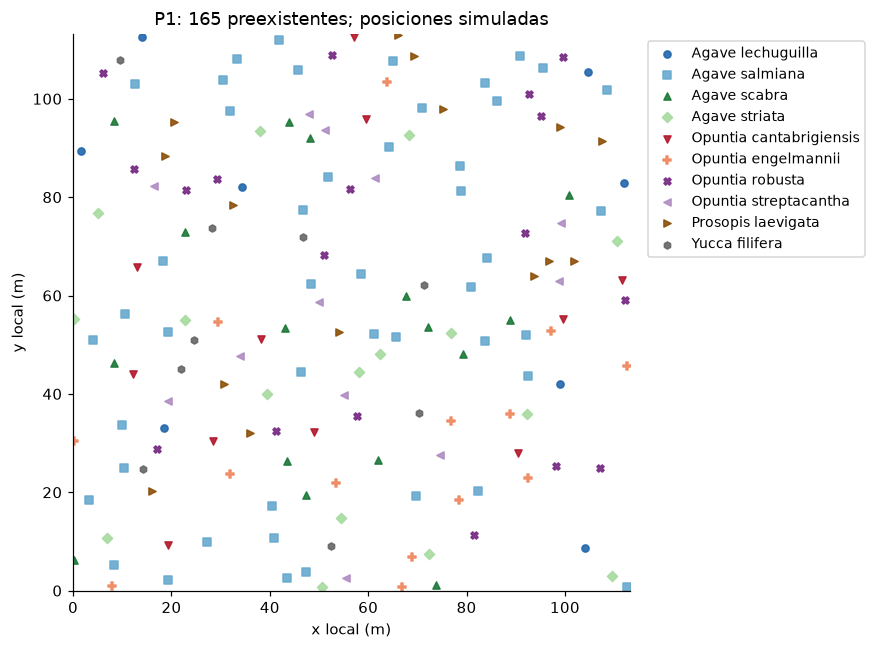

In [6]:
class EscenarioNoConstruido(ValueError):
    pass

def simular_existentes(n, limites, config, rng):
    d = config.separacion_min
    if d <= 0:
        raise ValueError('La separación mínima debe ser positiva.')
    puntos, cubetas = [], {}
    for _ in range(config.max_propuestas_posicion):
        if len(puntos) == int(n.sum()):
            break
        z = rng.uniform([0,0],limites)
        celda = tuple(np.floor(z/d).astype(int))
        vecinos = [j for dx in (-1,0,1) for dy in (-1,0,1)
                   for j in cubetas.get((celda[0]+dx,celda[1]+dy),[])]
        if any(np.linalg.norm(z-puntos[j]) < d for j in vecinos):
            continue
        cubetas.setdefault(celda,[]).append(len(puntos))
        puntos.append(z)
    if len(puntos) != int(n.sum()):
        raise EscenarioNoConstruido(f'Solo se generaron {len(puntos)}/{n.sum()} existentes; límite de intentos.')
    etiquetas = rng.permutation(np.repeat(np.arange(len(n)),n))
    return np.array(puntos).reshape(-1,2), etiquetas

def flujos(p, escenario, config):
    return [np.random.default_rng(s) for s in
            np.random.SeedSequence([config.semilla,p,escenario]).spawn(3)]

rng_pos, rng_base, rng_local = flujos(1,0,cfg)
F, f_especie = simular_existentes(n,limites,cfg,rng_pos)

def mapa(ax, puntos, etiquetas, titulo, limites, fijos=None):
    for s in range(K):
        mask = etiquetas == s
        ax.scatter(*puntos[mask].T,s=22,c=COLORES[s],marker=MARCAS[s],label=S[s],alpha=.9)
    if fijos is not None and len(fijos):
        ax.scatter(*puntos[fijos].T,s=65,facecolors='none',edgecolors='black',linewidths=.7,
                   label='Anillo: preexistente')
    ax.set(xlim=(0,limites[0]),ylim=(0,limites[1]),aspect='equal',
           xlabel='x local (m)',ylabel='y local (m)',title=titulo)

fig,ax=plt.subplots(figsize=(11,6))
mapa(ax,F,f_especie,'P1: 165 preexistentes; posiciones simuladas',limites)
ax.legend(bbox_to_anchor=(1.02,1),loc='upper left',fontsize=9)
fig.tight_layout()
guardar_figura('02_existentes')

## 7. Generación de posiciones candidatas para nuevas plantas
Filas alternadas desplazadas medio paso forman el tresbolillo. Se descartan las candidatas demasiado cercanas a una existente. Si quedan menos de las necesarias, se informa capacidad insuficiente **de esta malla y escenario**, no infactibilidad universal.

Se eligen sucesivamente las candidatas más alejadas del conjunto ya ocupado (existentes y candidatas seleccionadas). Es una regla geométrica reproducible, sin usar especies. No se calculan ni almacenan matrices completas de distancias.

Candidatas admisibles: 731; seleccionadas: 677


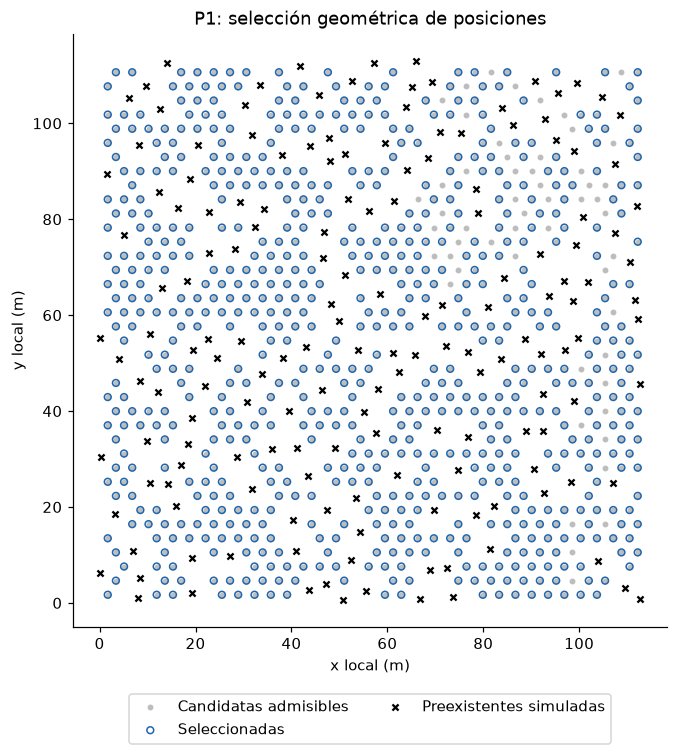

Paso 3.400 m: factible; 731 candidatas.
Paso 4.189 m: Capacidad de malla 491 < demanda 677.
El diagnóstico no altera cfg ni las posiciones del caso principal.


In [7]:
def candidatas(F, limites, cantidad, config):
    paso, minimo = config.paso_malla, config.separacion_min
    if paso < minimo or minimo <= 0:
        raise ValueError('El paso de la malla debe ser >= separación mínima > 0.')
    filas=[]
    for j,y in enumerate(np.arange(paso/2,limites[1],paso*np.sqrt(3)/2)):
        xs=np.arange(paso/2+(j%2)*paso/2,limites[0],paso)
        filas.extend((x,y) for x in xs)
    malla=np.array(filas).reshape(-1,2)
    dist=cKDTree(F).query(malla)[0] if len(F) else np.full(len(malla),np.inf)
    pool=malla[dist >= minimo-1e-9]
    if len(pool)<cantidad:
        raise EscenarioNoConstruido(f'Capacidad de malla {len(pool)} < demanda {cantidad}.')
    cercano=cKDTree(F).query(pool)[0] if len(F) else np.full(len(pool),np.inf)
    elegidas=[]
    for _ in range(cantidad):
        i=int(np.argmax(cercano))
        elegidas.append(i)
        cercano=np.minimum(cercano,np.linalg.norm(pool-pool[i],axis=1))
        cercano[elegidas]=-np.inf
    return pool, pool[np.array(elegidas,dtype=int)]

pool,V = candidatas(F,limites,int(q.sum()),cfg)
print(f'Candidatas admisibles: {len(pool)}; seleccionadas: {len(V)}')
fig,ax=plt.subplots(figsize=(8,7))
ax.scatter(*pool.T,c='#bdbdbd',s=8,label='Candidatas admisibles')
ax.scatter(*V.T,facecolors='none',edgecolors='#2166ac',s=20,label='Seleccionadas')
ax.scatter(*F.T,c='black',s=16,marker='x',label='Preexistentes simuladas')
ax.set(xlabel='x local (m)',ylabel='y local (m)',aspect='equal',title='P1: selección geométrica de posiciones')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.10),ncol=2)
guardar_figura('03_candidatas')

paso_658=float(np.sqrt(10000/(np.sqrt(3)/2*658)))
for paso in [3.4,paso_658]:
    diagnostico=replace(cfg,paso_malla=paso)
    try:
        ps,vs=candidatas(F,limites,int(q.sum()),diagnostico)
        print(f'Paso {paso:.3f} m: factible; {len(ps)} candidatas.')
    except EscenarioNoConstruido as e:
        print(f'Paso {paso:.3f} m:',e)
print('El diagnóstico no altera cfg ni las posiciones del caso principal.')

## 8. Construcción del grafo espacial
`cKDTree.query_pairs` devuelve únicamente pares dentro del radio. NetworkX conserva los identificadores `(p, i)`; arreglos de índices locales aceleran la evaluación. No hay aristas entre polígonos distintos. En el gráfico se muestra una muestra determinista de aristas para evitar saturación visual.

Vértices: 842 Aristas: 3082


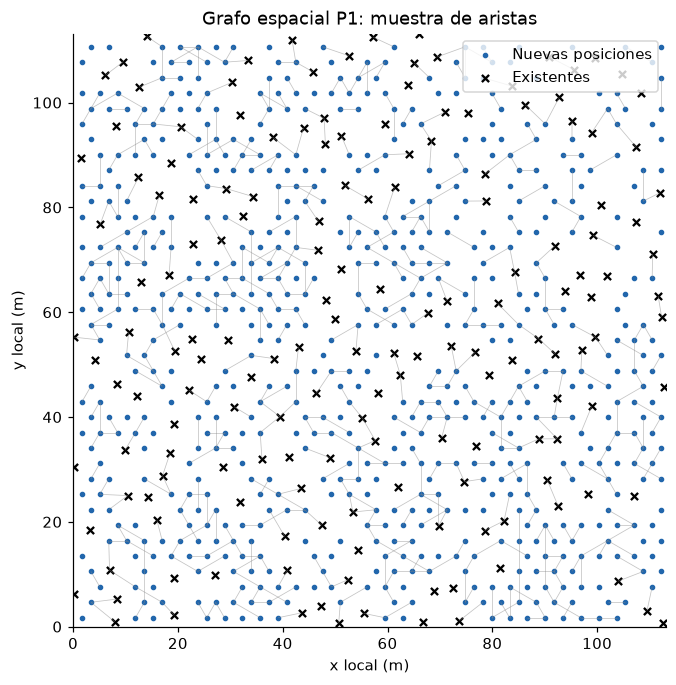

In [8]:
def construir_grafo(p, F, V, config):
    if config.radio <= 0:
        raise ValueError('Radio debe ser positivo.')
    U=np.vstack([F,V])
    pares=cKDTree(U).query_pairs(config.radio,output_type='ndarray')
    dist=np.linalg.norm(U[pares[:,0]]-U[pares[:,1]],axis=1)
    pesos=np.maximum(0,1-dist/config.radio)
    G=nx.Graph()
    G.add_nodes_from(((p,i),{'pos':tuple(z),'fija':i<len(F)}) for i,z in enumerate(U))
    G.add_weighted_edges_from(((p,int(i)),(p,int(j)),float(w)) for (i,j),w in zip(pares,pesos))
    ady=[[] for _ in U]
    for (i,j),w in zip(pares,pesos):
        ady[i].append((int(j),float(w)))
        ady[j].append((int(i),float(w)))
    return {'U':U,'pares':pares,'pesos':pesos,'G':G,'ady':ady,'nf':len(F),'p':p}

g=construir_grafo(1,F,V,cfg)
print('Vértices:',len(g['G']),'Aristas:',g['G'].number_of_edges())
fig,ax=plt.subplots(figsize=(7,7))
e=g['pares'][::max(1,len(g['pares'])//450)]
ax.add_collection(LineCollection(g['U'][e],colors='#888888',linewidths=.5,alpha=.5))
ax.scatter(*V.T,s=7,c='#2166ac',label='Nuevas posiciones')
ax.scatter(*F.T,s=22,c='black',marker='x',label='Existentes')
ax.set(xlim=(0,limites[0]),ylim=(0,limites[1]),aspect='equal',xlabel='x local (m)',
       ylabel='y local (m)',title='Grafo espacial P1: muestra de aristas')
ax.legend()
guardar_figura('04_grafo')

## 9. Definición de la matriz de competencia
**Supuesto de prueba, no evidencia científica:** 3 para la misma especie, 2 para distintas especies del mismo género y 1 para géneros diferentes. La matriz simétrica `C` puede sustituirse por otra calibrada, sin modificar los algoritmos. El grafo entre especies es conceptual; el grafo que optimizamos es el espacial.

,Agave lechuguilla,Agave salmiana,Agave scabra,Agave striata,Opuntia cantabrigiensis,Opuntia engelmannii,Opuntia robusta,Opuntia streptacantha,Prosopis laevigata,Yucca filifera
Agave lechuguilla,3.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0
Agave salmiana,2.0,3.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0
Agave scabra,2.0,2.0,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0
Agave striata,2.0,2.0,2.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0
Opuntia cantabrigiensis,1.0,1.0,1.0,1.0,3.0,2.0,2.0,2.0,1.0,1.0
Opuntia engelmannii,1.0,1.0,1.0,1.0,2.0,3.0,2.0,2.0,1.0,1.0
Opuntia robusta,1.0,1.0,1.0,1.0,2.0,2.0,3.0,2.0,1.0,1.0
Opuntia streptacantha,1.0,1.0,1.0,1.0,2.0,2.0,2.0,3.0,1.0,1.0
Prosopis laevigata,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0
Yucca filifera,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0


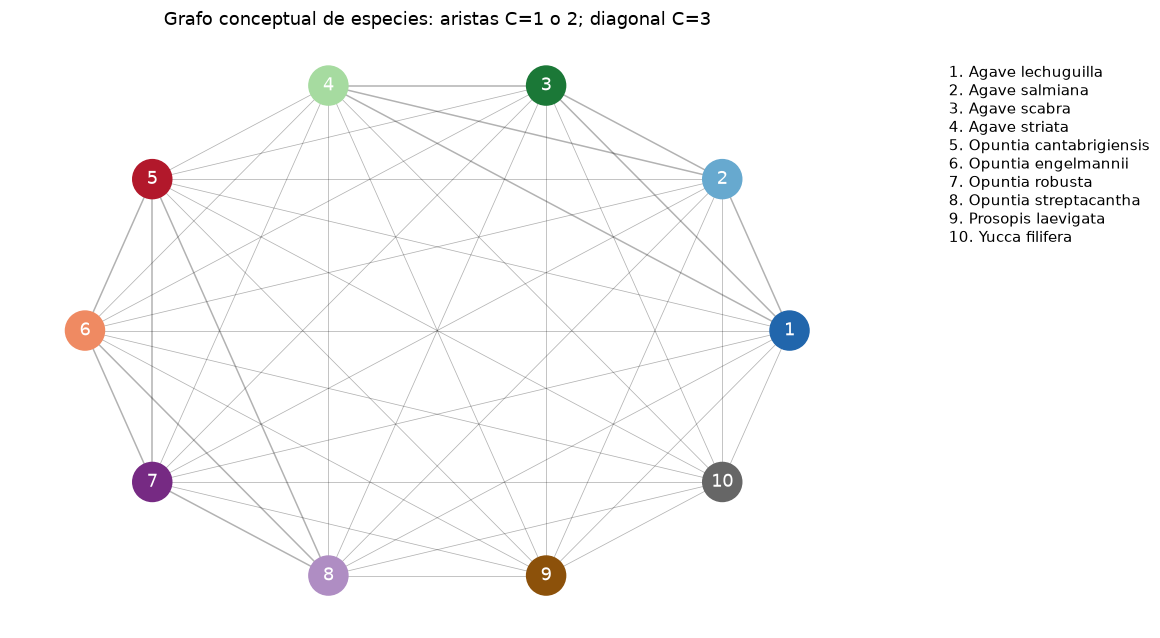

In [9]:
def matriz_competencia(especies, misma=3., genero=2., distinta=1.):
    generos=especies.genero.to_numpy()
    C=np.where(generos[:,None]==generos[None,:],genero,distinta).astype(float)
    np.fill_diagonal(C,misma)
    return C

def validar_C(C):
    if C.shape!=(K,K) or not np.isfinite(C).all() or (C<0).any() or not np.allclose(C,C.T):
        raise ValueError('C debe ser finita, no negativa, simétrica y de tamaño 10x10.')

C=matriz_competencia(especies)
validar_C(C)
display(pd.DataFrame(C,index=S,columns=S))
fig,ax=plt.subplots(figsize=(10,7))
H=nx.Graph()
H.add_nodes_from(range(K))
H.add_weighted_edges_from((s,t,C[s,t]) for s in range(K) for t in range(s+1,K))
pos=nx.circular_layout(H)
nx.draw_networkx_edges(H,pos,ax=ax,width=[.5*H[u][v]['weight'] for u,v in H.edges],alpha=.3)
nx.draw_networkx_nodes(H,pos,ax=ax,node_color=COLORES,node_size=650)
nx.draw_networkx_labels(H,pos,ax=ax,labels={i:str(i+1) for i in range(K)},font_color='white')
ax.text(1.1,.95,'\n'.join(f'{i+1}. {s}' for i,s in enumerate(S)),transform=ax.transAxes,va='top')
ax.set_title('Grafo conceptual de especies: aristas C=1 o 2; diagonal C=3')
ax.axis('off')
guardar_figura('05_especies')

## 10. Implementación de la función objetivo
Se evalúa el mismo índice adimensional para la base, DSATUR y búsqueda local. La competencia modificable es $J_{FV}+J_{VV}$; reportamos también el total con $J_{FF}$.

In [10]:
def objetivo(etiquetas,g,C,desglose=False):
    if len(etiquetas)!=len(g['U']) or np.any((etiquetas<0)|(etiquetas>=len(C))):
        raise ValueError('La función objetivo requiere una asignación completa.')
    i,j=g['pares'].T
    valores=g['pesos']*C[etiquetas[i],etiquetas[j]]
    if not desglose:
        return float(valores.sum())
    ff=(i<g['nf'])&(j<g['nf'])
    vv=(i>=g['nf'])&(j>=g['nf'])
    return {'FF':float(valores[ff].sum()),'FV':float(valores[~(ff|vv)].sum()),
            'VV':float(valores[vv].sum()),'total':float(valores.sum())}

def base_aleatoria(fijas,q,rng):
    return np.r_[fijas,rng.permutation(np.repeat(np.arange(len(q)),q))]

t0=perf_counter()
y_base=base_aleatoria(f_especie,q,rng_base)
t_base=perf_counter()-t0
display(pd.Series(objetivo(y_base,g,C,True),name='Base aleatoria'))

FF         23.177216
FV        218.818216
VV        847.011195
total    1089.006627
Name: Base aleatoria, dtype: float64

## 11. Implementación de DSATUR adaptado
La saturación de una posición es el **número de especies distintas entre vecinos ya asignados**, incluyendo preexistentes. Se selecciona lexicográficamente por: (1) saturación, (2) grado ponderado, (3) menor índice local. Para cada especie con cuota restante positiva se calcula
$$\Delta_i(s)=\sum_{j\in N(i):\,j\text{ asignado}}w_{ij}C_{s,s_j}.$$
Se elige el menor incremento; en empate, la mayor cuota restante y luego el menor índice de especie. No se prohíbe repetir color vecino: se penaliza. No se minimiza el número de colores.

Como todas las posiciones seleccionadas admiten las diez especies y las cuotas suman exactamente las posiciones vacantes, siempre existe una especie disponible hasta terminar. Si se agregan incompatibilidades duras por especie, esta garantía desaparece y habría que añadir verificación de factibilidad y reparación. El recorrido actual cuesta aproximadamente $O(|V||U|+K|E|)$ y no certifica optimalidad.

In [11]:
def dsatur(fijas,q,g,C):
    validar_C(C)
    nf,N=len(fijas),len(g['U'])
    if len(q)!=len(C) or np.any(q<0) or np.any(q%1) or int(q.sum())!=N-nf:
        raise ValueError('Cuotas inválidas o incompatibles con el número de posiciones.')
    y=np.full(N,-1,dtype=int)
    y[:nf]=fijas
    restante=q.astype(int).copy()
    vistos=np.zeros((N,len(C)),dtype=bool)
    coste=np.zeros((N,len(C)))
    grado=np.array([sum(w for _,w in ad) for ad in g['ady']])
    def actualizar(i,s):
        for j,w in g['ady'][i]:
            if y[j]<0:
                vistos[j,s]=True
                coste[j]+=w*C[:,s]
    for i,s in enumerate(fijas):
        actualizar(i,int(s))
    for _ in range(N-nf):
        libres=np.flatnonzero(y<0)
        saturacion=vistos[libres].sum(axis=1)
        i=int(libres[np.lexsort((libres,-grado[libres],-saturacion))[0]])
        factibles=np.flatnonzero(restante>0)
        if not len(factibles):
            raise ValueError('No queda especie factible.')
        s=int(min(factibles,key=lambda s:(coste[i,s],-restante[s],s)))
        y[i]=s
        restante[s]-=1
        actualizar(i,s)
    assert not restante.any()
    return y

t0=perf_counter()
y_dsatur=dsatur(f_especie,q,g,C)
t_dsatur=perf_counter()-t0
print(f'DSATUR: {objetivo(y_dsatur,g,C):.3f}; tiempo {t_dsatur:.3f} s')

DSATUR: 991.748; tiempo 0.039 s


## 12. Mejora mediante búsqueda local
Se proponen pares uniformes de posiciones **nuevas** y se intercambian sus especies si $\Delta J<0$. Se recorren solo las aristas incidentes; la arista entre los dos vértices no cambia al intercambiar especies porque $C$ es simétrica. Las cuotas y las preexistentes se conservan por construcción.

El presupuesto de propuestas es configurable. Terminar el presupuesto no prueba un óptimo local respecto a todos los intercambios, ni un óptimo global. La trayectoria registra solo mejoras aceptadas; cada salto corresponde a una evaluación real.

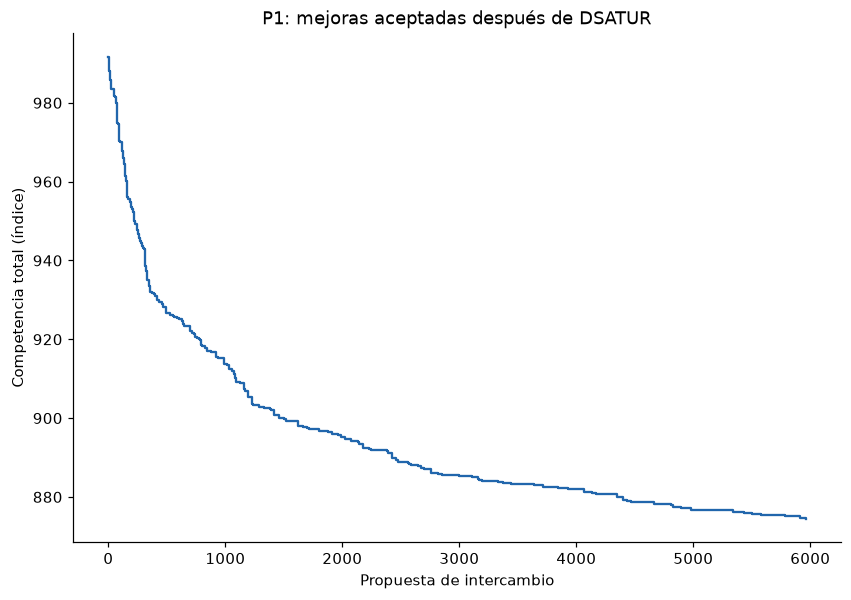

Antes: 991.748; después: 874.525


In [12]:
def delta_intercambio(a,b,y,g,C):
    sa,sb=int(y[a]),int(y[b])
    return sum(w*(C[sb,y[j]]-C[sa,y[j]]) for j,w in g['ady'][a] if j!=b) + sum(
        w*(C[sa,y[j]]-C[sb,y[j]]) for j,w in g['ady'][b] if j!=a)

def busqueda_local(inicial,g,C,rng,intentos):
    y=inicial.copy()
    valor=objetivo(y,g,C)
    historia=[(0,valor)]
    movibles=np.arange(g['nf'],len(y))
    if len(movibles)<2:
        return y,np.array(historia)
    for intento in range(1,intentos+1):
        a,b=rng.choice(movibles,2,replace=False)
        if y[a]==y[b]:
            continue
        delta=delta_intercambio(a,b,y,g,C)
        if delta < -1e-10:
            y[a],y[b]=y[b],y[a]
            valor+=delta
            historia.append((intento,valor))
    assert np.isclose(valor,objetivo(y,g,C),atol=1e-7)
    return y,np.array(historia)

t0=perf_counter()
y_final,historia=busqueda_local(y_dsatur,g,C,rng_local,cfg.intentos_local)
t_local=perf_counter()-t0
fig,ax=plt.subplots()
ax.step(historia[:,0],historia[:,1],where='post',color='#2166ac')
ax.set(xlabel='Propuesta de intercambio',ylabel='Competencia total (índice)',
       title='P1: mejoras aceptadas después de DSATUR')
guardar_figura('06_busqueda_local')
print(f'Antes: {objetivo(y_dsatur,g,C):.3f}; después: {objetivo(y_final,g,C):.3f}')

## 13. Visualización de la distribución optimizada
Los anillos identifican plantas preexistentes; los símbolos y colores identifican especies. La geometría es simulada y no georreferenciada.

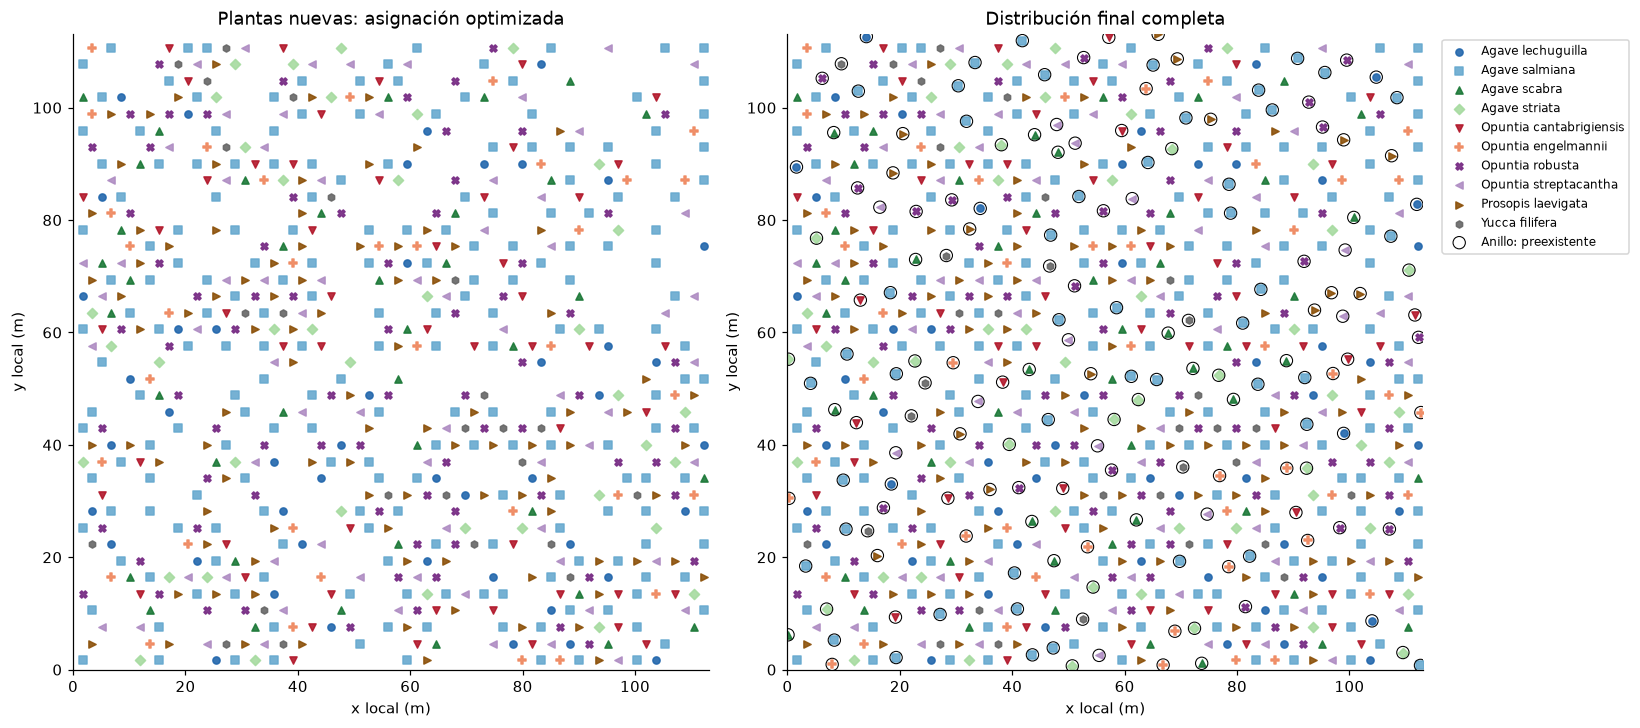

,especie,costo_unitario,existentes,meta_final,nuevas,costo_nuevas_um,final_verificado
0,Agave lechuguilla,26.0,8,54,46,1196.0,54
1,Agave salmiana,26.0,46,251,205,5330.0,251
2,Agave scabra,26.0,16,54,38,988.0,54
3,Agave striata,26.0,16,54,38,988.0,54
4,Opuntia cantabrigiensis,18.0,11,63,52,936.0,63
5,Opuntia engelmannii,21.0,14,48,34,714.0,48
6,Opuntia robusta,18.0,18,93,75,1350.0,93
7,Opuntia streptacantha,18.0,12,82,70,1260.0,82
8,Prosopis laevigata,26.5,15,110,95,2517.5,110
9,Yucca filifera,26.0,9,33,24,624.0,33


Validaciones de las tres soluciones: correctas.


In [13]:
fig,axs=plt.subplots(1,2,figsize=(15,7))
mapa(axs[0],V,y_final[len(F):],'Plantas nuevas: asignación optimizada',limites)
mapa(axs[1],g['U'],y_final,'Distribución final completa',limites,np.arange(len(F)))
axs[1].legend(bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8)
fig.tight_layout()
guardar_figura('07_distribucion_final')

def validar_solucion(y,g,fijas,n,R,limites,config):
    U=g['U']
    assert y.shape==(len(U),) and np.all((y>=0)&(y<K))
    assert np.array_equal(y[:len(fijas)],fijas)
    assert np.array_equal(np.bincount(y[:len(fijas)],minlength=K),n)
    assert np.array_equal(np.bincount(y,minlength=K),R)
    assert len(U)==int(R.sum())
    assert np.all(U>=0) and np.all(U<=limites)
    assert len(np.unique(U,axis=0))==len(U)
    assert len(cKDTree(U).query_pairs(config.separacion_min-1e-8))==0
    assert len(set(g['G'].nodes))==len(U)
    return True

for y in [y_base,y_dsatur,y_final]:
    validar_solucion(y,g,f_especie,n,R,limites,cfg)
assert np.array_equal(g['U'][:len(F)],F)
assert objetivo(y_final,g,C)<=objetivo(y_dsatur,g,C)+1e-8
assert (np.diff(historia[:,1])<=1e-8).all()
tabla_cuotas['final_verificado']=np.bincount(y_final,minlength=K)
display(tabla_cuotas)
pd.DataFrame({'poligono':1,'indice_local':np.arange(len(y_final)),
    'x_simulada_m':g['U'][:,0],'y_simulada_m':g['U'][:,1],
    'preexistente':np.arange(len(y_final))<len(F),
    'especie':[S[s] for s in y_final]}).to_csv(OUT/'distribucion_simulada_p1.csv',index=False)
print('Validaciones de las tres soluciones: correctas.')

## 14. Simulación Monte Carlo de escenarios espaciales
Se regenera el escenario completo y se reoptimiza tras observar sus posiciones: es un experimento **con adaptación a cada escenario**, no una única decisión robusta previa a conocer el terreno. En cada escenario se mantienen exactamente los conteos y la compra.

Se usan flujos independientes para posiciones, base y búsqueda local. Las semillas dependen de `(semilla, polígono, escenario)`, de modo que el orden de ejecución no cambia un resultado. DSATUR es determinista. La variación observada mezcla el escenario espacial, una base aleatoria por escenario y las propuestas locales; no representa exclusivamente incertidumbre ecológica.

Se conservan y reportan los fallos de construcción, sin reemplazarlos por nuevas simulaciones. Las estadísticas se condicionan a los escenarios completados; se informa el denominador. Doce corridas son exploratorias, no evidencia de convergencia.

In [14]:
def ejecutar_escenario(p, escenario, config=cfg, C=C):
    inicio=perf_counter()
    area,n,R,q=datos_poligono(p,config)
    limites=dimensiones(area,config)
    rp,rb,rl=flujos(p,escenario,config)
    F,fijas=simular_existentes(n,limites,config,rp)
    pool,V=candidatas(F,limites,int(q.sum()),config)
    g=construir_grafo(p,F,V,config)
    tiempo_geometria=perf_counter()-inicio
    t=perf_counter(); base=base_aleatoria(fijas,q,rb); tb=perf_counter()-t
    t=perf_counter(); ds=dsatur(fijas,q,g,C); td=perf_counter()-t
    t=perf_counter(); final,h=busqueda_local(ds,g,C,rl,config.intentos_local); tl=perf_counter()-t
    for y in [base,ds,final]:
        validar_solucion(y,g,fijas,n,R,limites,config)
    assert np.array_equal(g['U'][:len(F)],F)
    jb,jd,jf=[objetivo(y,g,C) for y in [base,ds,final]]
    fijo=objetivo(final,g,C,True)['FF']
    assert jf<=jd+1e-8
    fila={'poligono':p,'escenario':escenario,'estado':'ok','detalle':'',
        'existentes':int(n.sum()),'nuevas':int(q.sum()),'total':int(R.sum()),
        'candidatas':len(pool),'J_base':jb,'J_dsatur':jd,'J_final':jf,'J_fijo':fijo,
        'mejora_pct':100*(jb-jf)/jb if jb else np.nan,
        'mejora_modificable_pct':100*(jb-jf)/(jb-fijo) if jb>fijo else np.nan,
        'costo_um':float(q@especies.costo_unitario.to_numpy()),
        'seg_geometria':tiempo_geometria,'seg_base':tb,'seg_dsatur':td,'seg_local':tl,
        'seg_total':perf_counter()-inicio}
    return fila,{'g':g,'base':base,'dsatur':ds,'final':final,'historia':h}

def monte_carlo(p,config=cfg,C=C):
    if config.escenarios<1:
        raise ValueError('Se requiere al menos un escenario.')
    filas=[]
    for e in range(config.escenarios):
        try:
            fila,_=ejecutar_escenario(p,e,config,C)
        except (EscenarioNoConstruido,ValueError) as error:
            fila={'poligono':p,'escenario':e,'estado':'fallo','detalle':str(error)}
        filas.append(fila)
    return pd.DataFrame(filas)

mc=monte_carlo(1,cfg,C)
mc.to_csv(OUT/'monte_carlo_p1.csv',index=False)
display(mc)
ok=mc.loc[mc.estado.eq('ok')].copy()
print(f'Escenarios completados: {len(ok)}/{len(mc)}; fallos: {len(mc)-len(ok)}')
if ok.empty:
    raise RuntimeError('Ningún escenario completado. Revisar los diagnósticos guardados.')
assert ok.existentes.eq(n.sum()).all() and ok.nuevas.eq(q.sum()).all()

,poligono,escenario,estado,detalle,existentes,nuevas,total,candidatas,J_base,J_dsatur,J_final,J_fijo,mejora_pct,mejora_modificable_pct,costo_um,seg_geometria,seg_base,seg_dsatur,seg_local,seg_total
0,1,0,ok,,165,677,842,731,1089.006627,991.747705,874.525183,23.177216,19.695146,20.123431,15903.5,0.038888,0.000080,0.035203,0.081359,0.157545
1,1,1,ok,,165,677,842,732,1122.558663,993.464204,885.377297,25.129048,21.128639,21.612445,15903.5,0.068699,0.000093,0.027945,0.068093,0.166777
2,1,2,ok,,165,677,842,728,1125.492833,997.707713,892.097343,24.232749,20.737181,21.193494,15903.5,0.029889,0.000076,0.029429,0.077795,0.139354
3,1,3,ok,,165,677,842,732,1112.031767,986.018953,884.175238,23.788857,20.490110,20.938021,15903.5,0.036268,0.000070,0.025857,0.075798,0.140096
4,1,4,ok,,165,677,842,741,1107.193714,1010.087701,891.929707,24.495669,19.442308,19.882183,15903.5,0.031762,0.000067,0.029183,0.085619,0.149888
5,1,5,ok,,165,677,842,741,1090.745849,977.907555,877.768238,25.109266,19.525869,19.985952,15903.5,0.038331,0.000054,0.030282,0.082575,0.153418
6,1,6,ok,,165,677,842,734,1091.916176,985.178452,880.364638,24.242108,19.374339,19.814243,15903.5,0.045079,0.000075,0.030849,0.084586,0.162634
7,1,7,ok,,165,677,842,752,1106.487730,963.969232,871.432375,23.795615,21.243377,21.710268,15903.5,0.031273,0.000076,0.035597,0.082205,0.151939
8,1,8,ok,,165,677,842,737,1103.107810,975.065426,876.343645,25.447243,20.556845,21.042263,15903.5,0.032540,0.000067,0.031658,0.090079,0.157390
9,1,9,ok,,165,677,842,726,1114.315938,995.844188,894.533914,30.692516,19.723493,20.282140,15903.5,0.043708,0.000130,0.033510,0.077556,0.157493


Escenarios completados: 12/12; fallos: 0


## 15. Comparación del algoritmo con una solución base
La base es una permutación uniforme del multiconjunto de nuevas especies: cumple exactamente las mismas cuotas, posiciones y restricciones. No pretende reproducir la secuencia histórica de siembra. Para cada escenario, la mejora es $100(J_{base}-J_{final})/J_{base}$. Una mejora negativa se conserva, no se oculta.

Los percentiles describen resultados de escenarios simulados; **no son intervalos de confianza**. Se calcula también el error estándar de la media como descripción Monte Carlo condicional al generador y al algoritmo. Los tiempos son mediciones de esta computadora; no son reproducibles bit a bit.

,metodo,FF,FV,VV,total,segundos_asignacion
0,Aleatoria,23.177216,218.818216,847.011195,1089.006627,0.000144
1,DSATUR,23.177216,190.996149,777.574340,991.747705,0.038811
2,DSATUR + local,23.177216,195.311922,656.036045,874.525183,0.119625


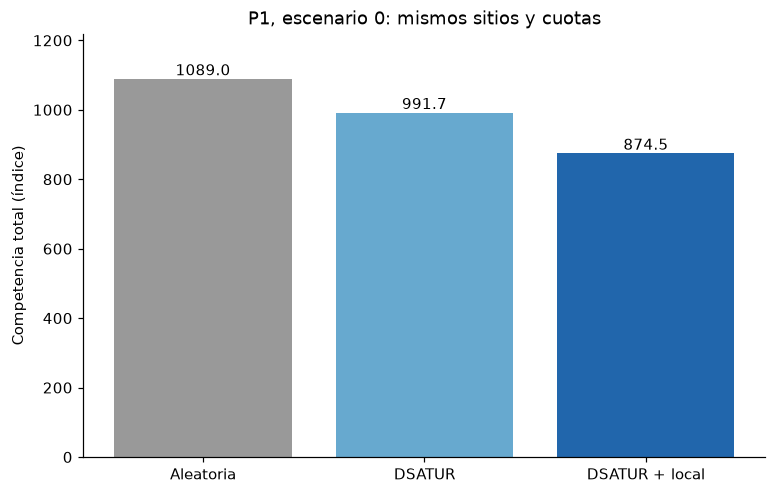

,count,mean,std,min,max,p05,p50,p95,error_estandar_media
J_base,12.0,1105.7434,12.8867,1089.0066,1125.4928,1089.7596,1106.8407,1123.8790,3.7201
J_dsatur,12.0,988.4515,12.0131,963.9692,1010.0877,970.0721,990.9600,1003.2787,3.4679
J_final,12.0,882.8562,7.3704,871.4324,894.5339,873.1334,882.3501,893.1938,2.1276
mejora_pct,12.0,20.1518,0.7221,19.2457,21.2434,19.3165,20.1068,21.1803,0.2085
mejora_modificable_pct,12.0,20.6290,0.7262,19.7657,21.7103,19.7924,20.6101,21.6565,0.2096
costo_um,12.0,15903.5000,0.0000,15903.5000,15903.5000,15903.5000,15903.5000,15903.5000,0.0000
seg_total,12.0,0.1519,0.0092,0.1384,0.1668,0.1389,0.1527,0.1645,0.0027


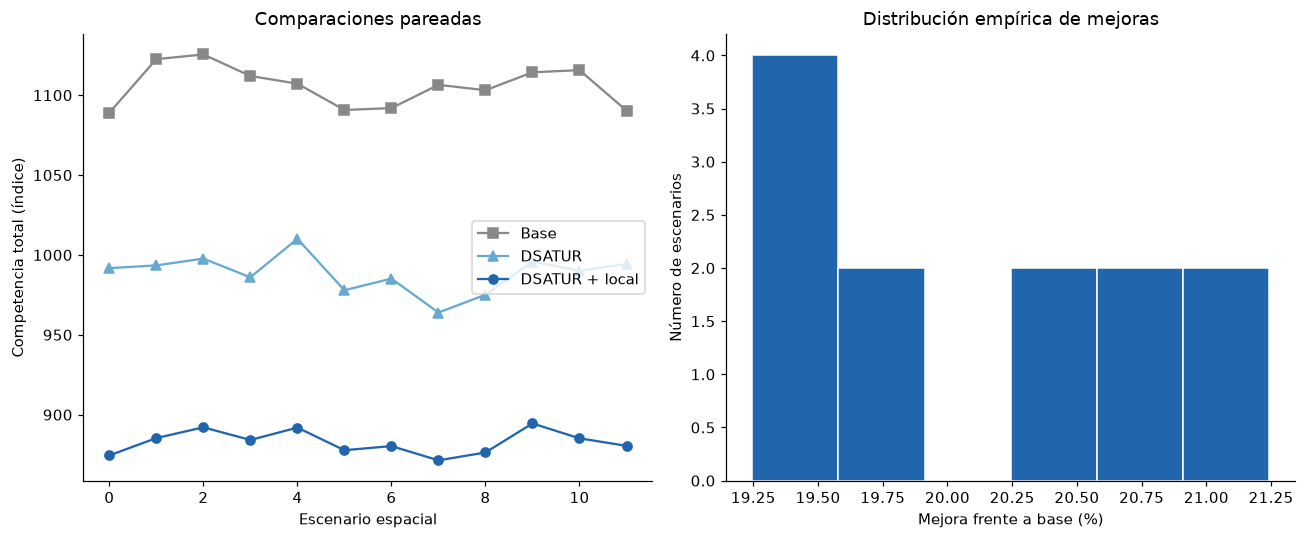

In [15]:
comparacion=pd.DataFrame([{'metodo':nombre,**objetivo(y,g,C,True),'segundos_asignacion':t}
    for nombre,y,t in [('Aleatoria',y_base,t_base),('DSATUR',y_dsatur,t_dsatur),
                       ('DSATUR + local',y_final,t_dsatur+t_local)]])
display(comparacion)
comparacion.to_csv(OUT/'comparacion_p1.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
ax.bar(comparacion.metodo,comparacion.total,color=['#999999','#67a9cf','#2166ac'])
for i,v in enumerate(comparacion.total): ax.text(i,v,f'{v:.1f}',ha='center',va='bottom')
ax.set(ylim=(0,comparacion.total.max()*1.12),ylabel='Competencia total (índice)',
       title='P1, escenario 0: mismos sitios y cuotas')
guardar_figura('08_comparacion')

metricas=['J_base','J_dsatur','J_final','mejora_pct','mejora_modificable_pct','costo_um','seg_total']
estadisticas=ok[metricas].agg(['count','mean','std','min','max']).T
estadisticas['p05']=ok[metricas].quantile(.05)
estadisticas['p50']=ok[metricas].quantile(.50)
estadisticas['p95']=ok[metricas].quantile(.95)
estadisticas['error_estandar_media']=estadisticas['std']/np.sqrt(estadisticas['count'])
display(estadisticas.round(4))
estadisticas.to_csv(OUT/'estadisticas_mc_p1.csv')

fig,axs=plt.subplots(1,2,figsize=(12,5))
for col,label,color,marker in [('J_base','Base','#888888','s'),('J_dsatur','DSATUR','#67a9cf','^'),
                             ('J_final','DSATUR + local','#2166ac','o')]:
    axs[0].plot(ok.escenario,ok[col],marker=marker,color=color,label=label)
axs[0].set(xlabel='Escenario espacial',ylabel='Competencia total (índice)',title='Comparaciones pareadas')
axs[0].legend()
axs[1].hist(ok.mejora_pct,bins=min(6,len(ok)),color='#2166ac',edgecolor='white')
axs[1].set(xlabel='Mejora frente a base (%)',ylabel='Número de escenarios',title='Distribución empírica de mejoras')
fig.tight_layout()
guardar_figura('09_monte_carlo')

### Verificación independiente y reproducibilidad
Se contrasta el objetivo vectorizado con una suma directa sobre NetworkX, se comprueba el cambio de objetivo de intercambios por recálculo completo y se repite el escenario 0. También se comprueban respuestas a cuotas y capacidad imposibles. Estas pruebas examinan propiedades del modelo, no solamente la presencia de resultados.

In [16]:
j_directo=sum(a['weight']*C[y_final[i[1]],y_final[j[1]]] for i,j,a in g['G'].edges(data=True))
assert np.isclose(j_directo,objetivo(y_final,g,C))
prueba_rng=np.random.default_rng(98)
for _ in range(30):
    a,b=prueba_rng.choice(np.arange(len(F),len(y_final)),2,replace=False)
    z=y_final.copy(); z[a],z[b]=z[b],z[a]
    assert np.isclose(objetivo(z,g,C)-objetivo(y_final,g,C),delta_intercambio(a,b,y_final,g,C))
_,repetido=ejecutar_escenario(1,0,cfg,C)
assert np.array_equal(repetido['g']['U'],g['U'])
assert np.array_equal(repetido['base'],y_base)
assert np.array_equal(repetido['dsatur'],y_dsatur)
assert np.array_equal(repetido['final'],y_final)
assert np.allclose(repetido['historia'],historia)
def debe_fallar(funcion):
    try: funcion()
    except ValueError: return True
    raise AssertionError('No se detectó la entrada inválida.')
assert debe_fallar(lambda: datos_poligono(1,replace(cfg,densidad=1)))
assert debe_fallar(lambda: dsatur(f_especie,q+1,g,C))
assert debe_fallar(lambda: candidatas(F,limites,100000,cfg))
assert debe_fallar(lambda: candidatas(F,limites,677,replace(cfg,separacion_min=4)))
# Caso sin plantas nuevas: no hay intercambios, pero el objetivo FF existe.
g0=construir_grafo(1,F,np.empty((0,2)),cfg)
y0=dsatur(f_especie,np.zeros(K,dtype=int),g0,C)
assert np.array_equal(y0,f_especie)
assert np.array_equal(busqueda_local(y0,g0,C,prueba_rng,10)[0],f_especie)
print('Objetivo, deltas, restricciones, repetición y casos límite: verificados.')
(OUT/'configuracion.json').write_text(json.dumps({'config':asdict(cfg),'versiones':versiones,
    'python':platform.python_version(),'matriz_C':C.tolist(),'validaciones':'correctas'},indent=2),encoding='utf-8')

Objetivo, deltas, restricciones, repetición y casos límite: verificados.


1731

## 16. Resultados preliminares, limitaciones y conclusiones
La interpretación siguiente se genera con los valores calculados. Una reducción del índice no demuestra aumento de supervivencia: faltan coeficientes ecológicos, coordenadas y contornos reales, pendientes, suelo, humedad y restricciones específicas de cada especie.

El costo solo comprende adquisición; no incluye transporte, mantenimiento, riego ni reposición. Con cuotas fijas es idéntico entre métodos y escenarios. La referencia presupuestal de la diapositiva 18 no se impone como restricción del prototipo.

**Cobertura de Entregable 2:** conjuntos, parámetros, variables, objetivo y restricciones (sección 4); probabilidades con inventario conocido (4 y 6); grafo espacial y de especies (8 y 9); heurística (11–12); resultados preliminares (13–16). La antigua incertidumbre de compra de `Entrega_1.md` se reemplaza aquí por incertidumbre espacial, de acuerdo con el inventario y la aclaración del equipo. No se han inventado requerimientos de agua.

La suma de áreas tabuladas puede diferir de las 183 ha aproximadas del proyecto; el cálculo usa cada área publicada. El valor editorial de P13 y la correspondencia entre IDs del mapa y tabla deben confirmarse antes de llevar el modelo al terreno.

In [17]:
mejora0=100*(objetivo(y_base,g,C)-objetivo(y_final,g,C))/objetivo(y_base,g,C)
display(Markdown(f"""**P1, escenario 0:** {n.sum()} plantas existentes + {q.sum()} nuevas = **{R.sum()} plantas**.
La densidad entera resultante es {R.sum()/area:.4f} plantas/ha; la diferencia frente a {cfg.densidad:g} se debe al redondeo.
Competencia base **{objetivo(y_base,g,C):.3f}**, DSATUR **{objetivo(y_dsatur,g,C):.3f}**,
y DSATUR + búsqueda local **{objetivo(y_final,g,C):.3f}**: mejora de **{mejora0:.2f}%** frente a la base.
Adquisición: **{tabla_cuotas.costo_nuevas_um.sum():,.2f} u.m.**

**Monte Carlo:** {len(ok)}/{len(mc)} escenarios completados; mejora media **{ok.mejora_pct.mean():.2f}%**,
desviación estándar **{ok.mejora_pct.std():.2f} puntos porcentuales**;
{int((ok.mejora_pct>0).sum())} escenarios mejoran respecto de su base.
El rango observado es {ok.mejora_pct.min():.2f}%–{ok.mejora_pct.max():.2f}%.
Estos resultados pertenecen exclusivamente a los supuestos y semillas configurados; no validan eficacia ecológica."""))

**P1, escenario 0:** 165 plantas existentes + 677 nuevas = **842 plantas**.
La densidad entera resultante es 657.8125 plantas/ha; la diferencia frente a 658 se debe al redondeo.
Competencia base **1089.007**, DSATUR **991.748**,
y DSATUR + búsqueda local **874.525**: mejora de **19.70%** frente a la base.
Adquisición: **15,903.50 u.m.**

**Monte Carlo:** 12/12 escenarios completados; mejora media **20.15%**,
desviación estándar **0.72 puntos porcentuales**;
12 escenarios mejoran respecto de su base.
El rango observado es 19.25%–21.24%.
Estos resultados pertenecen exclusivamente a los supuestos y semillas configurados; no validan eficacia ecológica.

## 17. Funciones reutilizables para ampliar el análisis a los 30 polígonos
Los CSV contienen los 30 inventarios. `datos_poligono`, `ejecutar_escenario` y `monte_carlo` reciben un ID de tabla. Se valida la aritmética de todos los polígonos sin ejecutar aún sus optimizaciones. Para ampliar, usar por ejemplo `ejecutar_lote([2,3], cfg, C)`; ejecutar todos exige solicitar explícitamente `list(range(1,31))` en la llamada.

En polígonos mayores, el recorrido DSATUR y la selección geométrica crecen aproximadamente de forma cuadrática; conviene medir un caso antes de aumentar escenarios. La selección de sitios, los escenarios agrupados y las cuotas flexibles son extensiones pendientes, no capacidades activas ocultas.

In [18]:
def ejecutar_lote(poligonos,config=cfg,C=C):
    if not poligonos:
        raise ValueError('Indique al menos un polígono.')
    return pd.concat([monte_carlo(int(p),config,C) for p in poligonos],ignore_index=True)

resumen_inventarios=[]
for p in range(1,31):
    a,nn,rr,qq=datos_poligono(p,cfg)
    resumen_inventarios.append({'poligono':p,'area_ha':a,'existentes':nn.sum(),
                               'meta_final':rr.sum(),'nuevas':qq.sum()})
resumen_inventarios=pd.DataFrame(resumen_inventarios)
resumen_inventarios.to_csv(OUT/'resumen_cuotas_30_poligonos.csv',index=False)
display(resumen_inventarios.head())
print('Datos y cuotas de 30 polígonos validados; optimización ejecutada solamente para P1.')
# Ejemplo optativo, descomentarlo cuando se decida ampliar:
# resultados_p2 = ejecutar_lote([2], replace(cfg, escenarios=3), C)

,poligono,area_ha,existentes,meta_final,nuevas
0,1,1.28,165,842,677
1,2,6.64,864,4369,3505
2,3,6.76,859,4448,3589
3,4,1.38,183,908,725
4,5,8.00,1003,5264,4261


Datos y cuotas de 30 polígonos validados; optimización ejecutada solamente para P1.
